# 7. Análise crítica

**CatBoost aplicado à previsão de churn**

Atividade Final de Aprendizado de Máquina I · FATEC Jundiaí · Ciência de Dados

| Aluna | Professor | Tema |
|:--|:--|:--|
| Mariana Costa de Mello | Mateus Guilherme Fuini | CatBoost |

## Modelos comparados

| Modelo | Família | Categóricas |
|:--|:--|:--|
| Regressão Logística | Linear | One-hot + padronização |
| KNN (k = 25) | Vizinhos | One-hot + padronização |
| Árvore de Decisão | Árvore única | One-hot |
| Random Forest | Bagging | One-hot |
| Gradient Boosting (scikit-learn) | Boosting clássico | One-hot |
| CatBoost | Boosting com árvores simétricas | Nativo |

Os encoders ficam dentro de pipelines, ajustados só no treino de cada fold. O CatBoost usa a configuração final do Notebook 6.

## Preparação

A mesma preparação é usada em todos os notebooks:

- `TotalCharges` vem como texto e os 11 valores em branco são de clientes com 0 meses de casa, então viram 0
- `customerID` sai porque é só um identificador
- Divisão estratificada em 60% treino, 20% validação e 20% teste, com semente 42

A primeira célula instala as bibliotecas; o `%%capture` esconde as mensagens da instalação.

In [1]:
%%capture
%pip install catboost shap category_encoders

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 3)
SEED = 42

df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].eq("Yes").astype(int)
cats = X.select_dtypes(exclude="number").columns.tolist()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

nums = ["tenure", "MonthlyCharges", "TotalCharges"]

def com_onehot(modelo, escalar=False):
    return make_pipeline(make_column_transformer((OneHotEncoder(handle_unknown="ignore"), cats), (StandardScaler() if escalar else "passthrough", nums)), modelo)

arvores = CatBoostClassifier(iterations=3000, depth=4, learning_rate=0.03, eval_metric="AUC", early_stopping_rounds=200, random_seed=SEED,
                             verbose=0, cat_features=cats).fit(X_train, y_train, eval_set=(X_val, y_val)).tree_count_

modelos = {
    "Regressão Logística": com_onehot(LogisticRegression(max_iter=2000), escalar=True),
    "KNN": com_onehot(KNeighborsClassifier(n_neighbors=25), escalar=True),
    "Árvore de Decisão": com_onehot(DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=SEED)),
    "Random Forest": com_onehot(RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": com_onehot(GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED)),
    "CatBoost": CatBoostClassifier(iterations=arvores, depth=4, learning_rate=0.03, random_seed=SEED, verbose=0),
}
ajuste = lambda nome: {"cat_features": cats} if nome == "CatBoost" else {}

## Validação cruzada

5 folds no treino + validação com `cross_validate`, que também mede o tempo de treino e de predição.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cvs = {nome: cross_validate(m, X_trval, y_trval, cv=cv, scoring=["roc_auc", "average_precision"], params=ajuste(nome)) for nome, m in modelos.items()}

comparacao = pd.DataFrame({nome: {"ROC-AUC": r["test_roc_auc"].mean(), "dp": r["test_roc_auc"].std(), "PR-AUC": r["test_average_precision"].mean(),
                                  "Treino (s)": r["fit_time"].mean(), "Predição (s)": r["score_time"].mean()} for nome, r in cvs.items()}).T
comparacao.sort_values("ROC-AUC", ascending=False).style.format("{:.3f}").highlight_max(subset=["ROC-AUC", "PR-AUC"], color="#d4e6f1")

,ROC-AUC,dp,PR-AUC,Treino (s),Predição (s)
CatBoost,0.850,0.012,0.671,4.076,0.014
Regressão Logística,0.846,0.013,0.661,0.207,0.042
Gradient Boosting,0.846,0.012,0.663,3.396,0.021
Random Forest,0.845,0.009,0.656,2.134,0.159
KNN,0.833,0.008,0.612,0.053,0.096
Árvore de Decisão,0.825,0.010,0.623,0.050,0.014


In [5]:
dif = pd.DataFrame({nome: cvs["CatBoost"]["test_roc_auc"] - r["test_roc_auc"] for nome, r in cvs.items() if nome != "CatBoost"})
pd.DataFrame({"Diferença média de AUC": dif.mean(), "Folds em que o CatBoost venceu": (dif > 0).sum()}).style.format({"Diferença média de AUC": "{:+.4f}"})

,Diferença média de AUC,Folds em que o CatBoost venceu
Regressão Logística,+0.0040,4
KNN,+0.0172,5
Árvore de Decisão,+0.0255,5
Random Forest,+0.0051,4
Gradient Boosting,+0.0041,5


## Conjunto de teste

Cada modelo treinado no treino + validação e avaliado uma vez no teste.

In [6]:
teste = {nome: roc_auc_score(y_test, m.fit(X_trval, y_trval, **ajuste(nome)).predict_proba(X_test)[:, 1]) for nome, m in modelos.items()}
pd.Series(teste, name="ROC-AUC no teste").sort_values(ascending=False).to_frame().style.format("{:.3f}")

,ROC-AUC no teste
CatBoost,0.846
Regressão Logística,0.842
Random Forest,0.842
Gradient Boosting,0.841
Árvore de Decisão,0.838
KNN,0.827


> **O CatBoost foi o melhor, mas por pouco.**

- Ganhou de todos na média e no teste (0,846), mas a diferença para a Regressão Logística é de só **0,004 de AUC**, e a Logística venceu em 1 dos 5 folds
- A Regressão Logística treina **dezenas de vezes mais rápido**
- O CatBoost é o mais rápido para prever entre os ensembles (cerca de 10 vezes mais que o Random Forest), por causa das árvores simétricas
- Modelos únicos (Árvore, KNN) ficam claramente atrás

## Curva de aprendizado

O `learning_curve` do scikit-learn treina cada modelo com frações crescentes dos dados e mede a AUC por validação cruzada. Mostra quem aproveita melhor poucos dados.

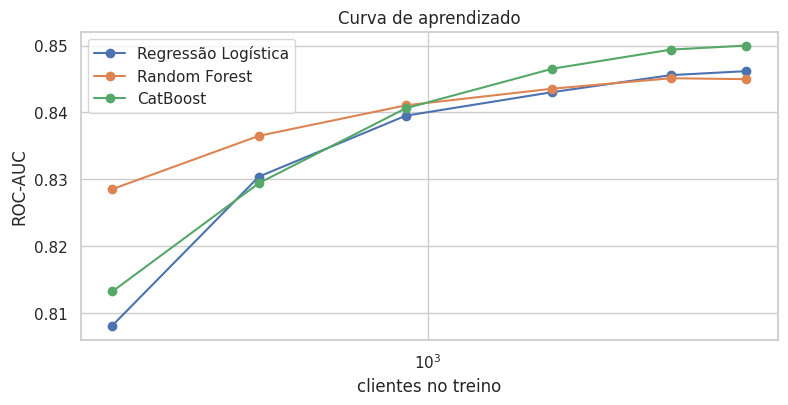

,Regressão Logística,Random Forest,CatBoost
225,0.808,0.829,0.813
450,0.830,0.837,0.829
901,0.840,0.841,0.841
1802,0.843,0.844,0.847
3154,0.846,0.845,0.849
4507,0.846,0.845,0.850


In [7]:
from sklearn.model_selection import learning_curve

tamanhos = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
curvas = {}
for nome in ["Regressão Logística", "Random Forest", "CatBoost"]:
    n, _, auc = learning_curve(modelos[nome], X_trval, y_trval, train_sizes=tamanhos, cv=cv, scoring="roc_auc", params=ajuste(nome))
    curvas[nome] = pd.Series(auc.mean(axis=1), index=n)

curvas = pd.DataFrame(curvas)
curvas.plot(marker="o", logx=True, figsize=(9, 4), xlabel="clientes no treino", ylabel="ROC-AUC", title="Curva de aprendizado")
plt.show()
curvas.style.format("{:.3f}")

> Com **poucos dados** (até ~450 clientes) o **Random Forest** foi melhor. Com ~900 clientes os dois empatam, e daí em diante o CatBoost fica na frente.

## Vantagens e limitações

| Vantagens | Limitações |
|:--|:--|
| Categóricas sem pré-processamento e com menos overfitting (E1) | Ganho pequeno sobre a Regressão Logística nesta base |
| Protege contra vazamento com alta cardinalidade (E5) | Treino bem mais lento que modelos lineares |
| Bom resultado com pouco ajuste (E2) | Pior que o Random Forest com poucos dados |
| Probabilidades calibradas e predição rápida | Explicação depende de SHAP, não de coeficientes |
| Early stopping, SHAP e ranqueamento já embutidos | Muitos comportamentos automáticos, menos transparente |

## Diferenças em relação à disciplina

| | Árvore de Decisão | Random Forest | Regressão Logística | CatBoost |
|:--|:--|:--|:--|:--|
| Ideia | Uma árvore | Árvores independentes | Modelo linear | Árvores em sequência |
| Reduz | | Variância | | Viés |
| Categóricas | Codificar antes | Codificar antes | Codificar antes | Nativo |
| Interações | Automáticas | Automáticas | Criar à mão | Automáticas |

## Limitações do estudo

- Uma base só, com categóricas de **poucos valores** (2 a 4), justamente onde o one-hot já funciona bem
- Sem data, então a divisão aleatória pode ser otimista
- Os modelos da disciplina não tiveram busca extensa de hiperparâmetros
- Sem comparação com XGBoost e LightGBM